# Lab 1: Convolutional architectures

This lab concerns developing convolution-based neural networks, based on the ConvNeXt paper, ["A ConvNet for the 2020s"](https://arxiv.org/abs/2201.03545) (Liu et al., CVPR 2022).

The lab has three parts:

1. **Theory intro** - we look inside pretrained ResNet-50 and ConvNeXt-T, and visualize a few ideas from the lecture.
2. **High-level usage** - use a pretrained ConvNeXt for similarity search, visualization, linear probing, and fine-tuning.
3. **Architecture deep-dive** - start from a small ResNet, and go all the way to ConvNeXt, applying changes one by one, to improve upon the neural network architecture.

Exercises to do are marked. In most places, you are supposed to fill in the `...` gaps. Subsequent cells have checks for your solution.

**Hardware** - use a GPU if you can. Free Google Colab T4 is enough (*Runtime -> Change runtime type -> T4 GPU*). CPU will work, but will be considerably slower. Note that in part 3 you can use lower-resolution images for weaker hardware if you need to.

## Environment setup

You can use a local environment with the [uv](https://docs.astral.sh/uv/) package manager, or [Google Colab](https://colab.research.google.com/). Everything was tested with `uv`: if you install packages manually with `pip`, something may break or not work because of incompatible versions.

### Local environment

1. Install uv [following the documentation](https://docs.astral.sh/uv/getting-started/installation/), if you don't have it yet.
2. In the directory of this lab, install the dependencies from `uv.lock`: `uv sync`
3. Run Jupyter Notebook: `uv run jupyter notebook`

Every lab has its own `pyproject.toml` and `uv.lock` files, so run these commands in the directory of this lab.

### Google Colab

Upload two files from the directory of this lab to the `/content` directory: `requirements.txt` and `datasets.py`, which contains the dataset code used in this notebook. Then install the dependencies by running `!pip install -r requirements.txt` in the cell below. If Colab asks you to restart the session afterwards, do it and continue with the next cell.

First a bit of general config.

In [1]:
# uncomment and run if using Google Colab
# !pip install -r requirements.txt

In [2]:
import copy
import math
import multiprocessing
import os
import random
import time
import warnings
from collections.abc import Callable
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms.v2 as T
from matplotlib_inline.backend_inline import set_matplotlib_formats
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torch.utils.flop_counter import FlopCounterMode

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# mixed precision (float16) training on CUDA GPUs
USE_AMP = device.type == "cuda"

# channels-last memory layout speeds up convolutions on CUDA GPUs
MEMORY_FORMAT = (
    torch.channels_last if device.type == "cuda" else torch.contiguous_format
)

# pick the fastest convolution algorithms for our shapes
torch.backends.cudnn.benchmark = True

print(
    f"PyTorch {torch.__version__}, torchvision {torchvision.__version__}, device: {device}"
)

PyTorch 2.14.1+cu130, torchvision 0.29.1+cu130, device: cuda


In [ ]:
# datasets are downloaded here: CUB-200-2011 (1.1 GB) and Imagenette (0.1-0.3 GB)
DATA_ROOT = "data"

# DataLoader worker processes, started as copies of this process ("fork")
# Windows uses spawn, not fork, so there they are started anew and import
# the dataset code from datasets.py
NUM_WORKERS = min(os.cpu_count(), 8)
if "fork" in multiprocessing.get_all_start_methods():
    multiprocessing.set_start_method("fork", force=True)

Now utility functions that we will use later.

In [ ]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def seed_everything(seed: int = 0) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def autocast() -> torch.autocast:
    # float16 mixed precision on CUDA
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)


def prepare_images(x: torch.Tensor) -> torch.Tensor:
    # uint8 images in [0, 255] -> normalized float images
    # float images are returned unchanged
    if x.dtype == torch.uint8:
        x = T.functional.normalize(x.float() / 255, IMAGENET_MEAN, IMAGENET_STD)
    return x


def denormalize(x: torch.Tensor) -> np.ndarray:
    # (3, H, W) tensor, normalized or uint8 -> (H, W, 3) numpy image in [0, 1]
    if x.dtype == torch.uint8:
        return x.permute(1, 2, 0).numpy()
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x.detach().cpu().float() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


def show_images(
    images: list,
    titles: list[str] | None = None,
    ncols: int = 6,
    size: float = 2.2,
    suptitle: str | None = None,
) -> None:
    nrows = math.ceil(len(images) / ncols)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(size * ncols, size * nrows + 0.4 * bool(suptitle))
    )
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for i, img in enumerate(images):
        axes[i].imshow(denormalize(img) if torch.is_tensor(img) else img)
        if titles is not None:
            axes[i].set_title(titles[i], fontsize=8)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())


def count_gmacs(model: nn.Module, img_size: int = 224) -> float:
    # GMAC = billions of multiply-accumulate operations
    # computational cost per image, called "FLOPs" in most papers
    was_training = model.training
    model.eval()
    x = torch.randn(1, 3, img_size, img_size, device=next(model.parameters()).device)
    with FlopCounterMode(display=False) as counter, torch.no_grad():
        model(x)
    model.train(was_training)
    return counter.get_total_flops() / 2 / 1e9


seed_everything(0)
plt.rcParams.update(
    {"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False}
)
# JPEG instead of PNG figures to make notebook smaller
set_matplotlib_formats("jpeg", pil_kwargs={"quality": 90})

# Theory intro

### CUB-200-2011 dataset

The [Caltech-UCSD Birds](https://www.vision.caltech.edu/datasets/cub_200_2011/) dataset has 200 bird species, with 5994 training and 5794 test images, so only about 30 labelled images per species. Many species differ only in small details (beak shape, wing bars, eye rings), which makes it a classic **fine-grained** classification benchmark.

The class to load it, `CUB200`, is in `datasets.py` (next to this notebook). It downloads the archive and reads the official train/test split.

CUB-200-2011: 5994 train / 5794 test images, 200 species


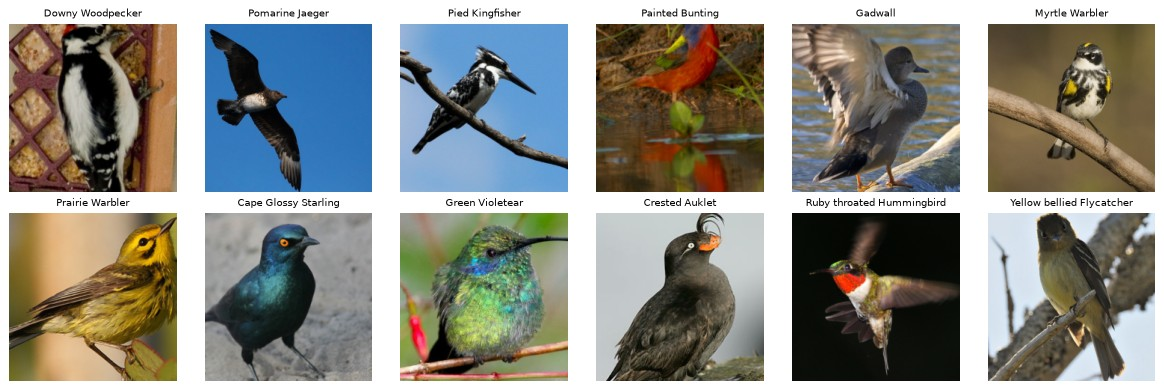

In [5]:
from datasets import CUB200

# deterministic evaluation transform of ImageNet models: resize, center crop, normalize
eval_tf = T.Compose(
    [
        T.ToImage(),
        T.Resize(256),
        T.CenterCrop(224),
        T.ToDtype(torch.float32, scale=True),
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)
cub_train = CUB200(DATA_ROOT, train=True, transform=eval_tf)
cub_test = CUB200(DATA_ROOT, train=False, transform=eval_tf)
bird_names = cub_train.classes
print(
    f"CUB-200-2011: {len(cub_train)} train / {len(cub_test)} test images, {len(bird_names)} species"
)

idx = np.random.choice(len(cub_train), 12, replace=False)
show_images([cub_train[i][0] for i in idx], [bird_names[cub_train[i][1]] for i in idx])

### 1.1 Stages and blocks

We'll now use two networks pretrained on ImageNet-1K from `torchvision`: the original **ResNet-50** (76.1% top-1 accuracy) and **ConvNeXt-T** (82.1%), which have a similar size and cost.

Both networks have the same macro structure:
- **stem** that downsamples the image 4x
- four **stages** of residual **blocks**, where every stage halves the resolution and doubles the channels
- **head** with global average pooling and linear classifier

Run the cell below to get a table with number of blocks, output shape, parameters and multiply-accumulate operations (MACs) of every part, for a 224x224 image. MACs are a hardware-agnostic measure of model performance, typically reported in billions, i.e. GMACs. This is often called the "FLOPs" in papers. We will use them throughout this notebook to measure computational cost.

Interesting elements to note:

* **stage compute ratio**: (3, 4, 6, 3) blocks in ResNet-50 vs (3, 3, 9, 3) in ConvNeXt-T
* ConvNeXt has **separate downsampling layers** between stages, while ResNet downsamples in the first block of each stage,
* parameters live mostly in the late stages (many channels), while compute is spread more evenly (early stages have high resolution)

In [6]:
from torchvision.models import (
    ConvNeXt_Tiny_Weights,
    ResNet50_Weights,
    convnext_tiny,
    resnet50,
)

resnet = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1).eval()
convnext = convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1).eval()


@torch.no_grad()
def describe_parts(
    model: nn.Module, parts: list[tuple[str, nn.Module]], img_size: int = 224
) -> None:
    # record the input of every part during one forward pass, then measure every part separately
    inputs = {}
    hooks = []
    for i, (name, part) in enumerate(parts):
        first = part[0] if isinstance(part, nn.Sequential) else part
        hooks.append(
            first.register_forward_pre_hook(
                lambda m, args, i=i: inputs.__setitem__(i, args[0])
            )
        )
    model(torch.randn(1, 3, img_size, img_size))
    for h in hooks:
        h.remove()

    total = count_gmacs(model, img_size)
    print(
        f"{'part':10s} {'blocks':>6s} {'output C x H x W':>18s} {'params':>8s} {'GMACs':>6s} {'% of GMACs':>11s}"
    )
    for i, (name, part) in enumerate(parts):
        with FlopCounterMode(display=False) as counter:
            out = part(inputs[i])
        gmacs = counter.get_total_flops() / 2e9
        blocks = len(part) if name.startswith("stage") else ""
        shape = " x ".join(map(str, out.shape[1:]))
        print(
            f"{name:10s} {blocks:>6} {shape:>18s} {count_params(part) / 1e6:7.2f}M {gmacs:6.2f} {100 * gmacs / total:10.1f}%"
        )
    print(
        f"{'total':10s} {'':>6s} {'':>18s} {count_params(model) / 1e6:7.2f}M {total:6.2f}\n"
    )


print("ResNet-50")
describe_parts(
    resnet,
    [
        ("stem", nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)),
        ("stage 1", resnet.layer1),
        ("stage 2", resnet.layer2),
        ("stage 3", resnet.layer3),
        ("stage 4", resnet.layer4),
        ("head", nn.Sequential(resnet.avgpool, nn.Flatten(), resnet.fc)),
    ],
)
print("ConvNeXt-T")
f = convnext.features
describe_parts(
    convnext,
    [
        ("stem", f[0]),
        ("stage 1", f[1]),
        ("downsample", f[2]),
        ("stage 2", f[3]),
        ("downsample", f[4]),
        ("stage 3", f[5]),
        ("downsample", f[6]),
        ("stage 4", f[7]),
        ("head", nn.Sequential(convnext.avgpool, convnext.classifier)),
    ],
)

1.3%

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /home/womackow/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100.0%
1.5%

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /home/womackow/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100.0%


ResNet-50
part       blocks   output C x H x W   params  GMACs  % of GMACs
stem                    64 x 56 x 56    0.01M   0.12        2.9%
stage 1         3      256 x 56 x 56    0.22M   0.67       16.3%
stage 2         4      512 x 28 x 28    1.22M   1.03       25.1%
stage 3         6     1024 x 14 x 14    7.10M   1.46       35.8%
stage 4         3       2048 x 7 x 7   14.96M   0.81       19.8%
head                            1000    2.05M   0.00        0.1%
total                                  25.56M   4.09

ConvNeXt-T
part       blocks   output C x H x W   params  GMACs  % of GMACs
stem                    96 x 56 x 56    0.00M   0.01        0.3%
stage 1         3       96 x 56 x 56    0.24M   0.74       16.6%
downsample             192 x 28 x 28    0.07M   0.06        1.3%
stage 2         3      192 x 28 x 28    0.92M   0.72       16.1%
downsample             384 x 14 x 14    0.30M   0.06        1.3%
stage 3         9      384 x 14 x 14   10.82M   2.11       47.4%
downsample     

Now one block of each network.

ResNet-50 **bottleneck block** goes wide -> narrow -> wide (256 -> 64 -> 256 channels in stage 1), with BatchNorm and ReLU after every convolution. We print the second block of stage 1, because the first block of every stage is special - is increases the number of channels for the new stage. As such, it also can't use residual connection directly (dimensions wouldn't match), and it uses a so-called projection shortcut instead (downsampling with 1x1 convolution). You will implement both kinds of shortcuts later.

**ConvNeXt block** goes narrow -> wide -> narrow (96 -> 384 -> 96): a 7x7 depthwise convolution (`groups=96`), one LayerNorm, and two pointwise layers with a single GELU between them. As pointwise 1x1 convolution is the same as `nn.Linear` (single-layer MLP) for every pixel, and the latter is a bit faster, `torchvision` uses that. We will see later that this is exactly the same operation.

In [7]:
print(resnet.layer1[1])
print()
print(convnext.features[1][0])

Bottleneck(
  (conv1): Conv2d(256, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
)

CNBlock(
  (block): Sequential(
    (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
    (1): Permute()
    (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
    (3): Linear(in_features=96, out_features=384, bias=True)
    (4): GELU(approximate='none')
    (5): Linear(in_features=384, out_features=96, bias=True)
    (6): Permute()
  )
  (stochastic_depth): Stochas

### 1.2 Learned filters

The first layer sees raw pixels, so its filters can be shown as small RGB images. ResNet-50 starts with 64 filters of size 7x7 (stride 2). ConvNeXt-T starts with the "patchify" stem: 96 filters of size 4x4 with stride 4, i.e. a linear projection of non-overlapping 4x4 patches, like the patch embedding of a Vision Transformer. On the right are the 7x7 **depthwise** kernels of the first ConvNeXt block: every one of the 96 channels has its own spatial filter (red = positive, blue = negative weights).

In [8]:
def filter_mosaic(
    w: torch.Tensor, ncols: int, signed: bool = False, pad: int = 1
) -> np.ndarray:
    # (N, C, k, k) filters -> one (H, W, C) image with a grid of filters, each normalized separately
    n, c, k, _ = w.shape
    if signed:  # scale to [-1, 1], keeping 0 in the middle of the color map
        w = w / w.abs().amax(dim=(1, 2, 3), keepdim=True)
    else:  # min-max scale to [0, 1]
        w = w - w.amin(dim=(1, 2, 3), keepdim=True)
        w = w / w.amax(dim=(1, 2, 3), keepdim=True)
    nrows = math.ceil(n / ncols)
    mosaic = torch.full(
        (c, nrows * (k + pad) + pad, ncols * (k + pad) + pad), 0.0 if signed else 1.0
    )
    for i in range(n):
        r, col = divmod(i, ncols)
        top, left = pad + r * (k + pad), pad + col * (k + pad)
        mosaic[:, top : top + k, left : left + k] = w[i]
    return mosaic.permute(1, 2, 0).squeeze(-1).numpy()

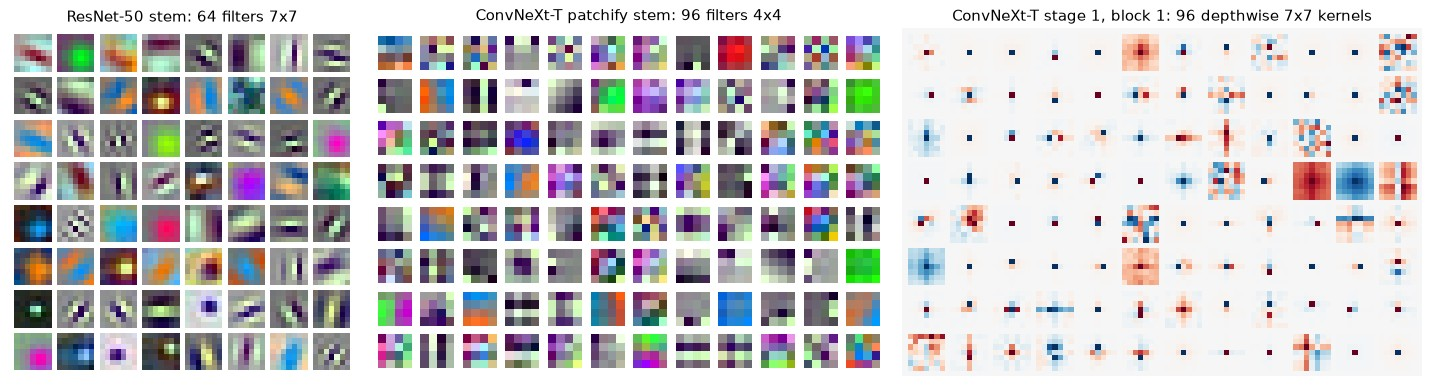

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), width_ratios=[8, 12, 12])
axes[0].imshow(filter_mosaic(resnet.conv1.weight.detach(), ncols=8))
axes[0].set_title("ResNet-50 stem: 64 filters 7x7")
axes[1].imshow(filter_mosaic(convnext.features[0][0].weight.detach(), ncols=12))
axes[1].set_title("ConvNeXt-T patchify stem: 96 filters 4x4")
dw_weight = convnext.features[1][0].block[0].weight.detach()  # (96, 1, 7, 7)
axes[2].imshow(
    filter_mosaic(dw_weight, ncols=12, signed=True), cmap="RdBu_r", vmin=-1, vmax=1
)
axes[2].set_title("ConvNeXt-T stage 1, block 1: 96 depthwise 7x7 kernels")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

ResNet-50 learned oriented edge detectors at several frequencies and color blobs, much like Gabor filters (and neurons in the primary visual cortex). The 4x4 patchify filters are tiny, but show similar edge and color patterns.

The depthwise kernels are different: most of them are not edge detectors, but move information around. Many are a single sharp peak, either in the center (the channel passes through almost unchanged) or shifted away from it (the channel is copied from a neighbouring location). Others are smooth blobs (local averaging) or center-surround patterns. This is how a large depthwise kernel gathers context from the surroundings, a bit like attention in a Transformer, while the 1x1 layers do all the channel mixing.

### 1.3 Feature maps through the stages

Next, the feature maps of ConvNeXt-T for one image, after each stage (6 channels with the highest spatial variance per stage). Early stages have high resolution and respond to local patterns (edges, texture of feathers). Later stages have low resolution and respond to larger object parts.

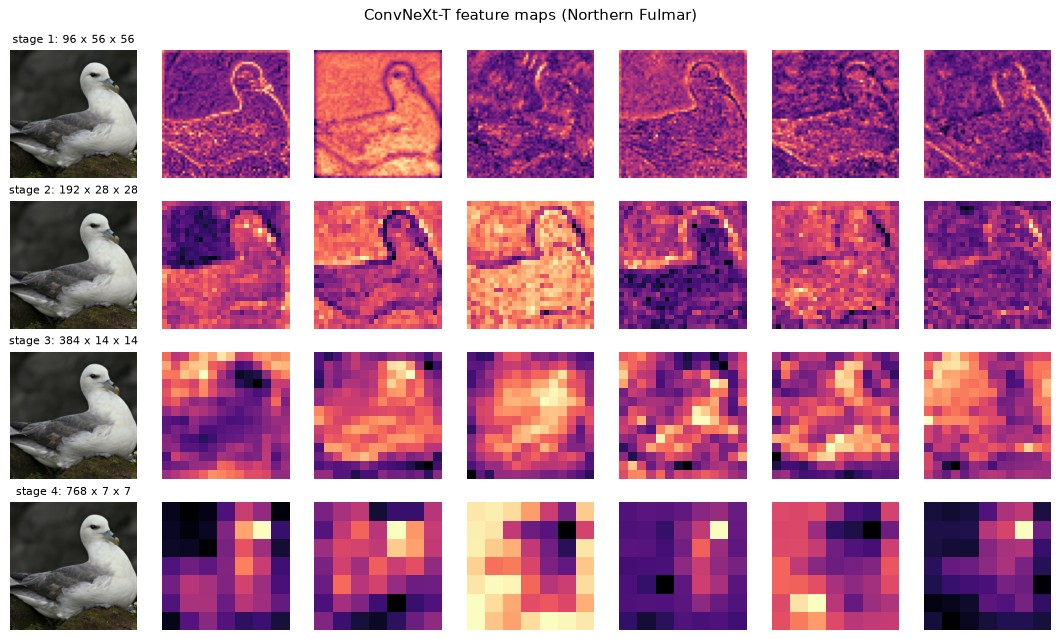

In [10]:
img, label = cub_test[1234]
feature_maps = {}
hooks = [
    convnext.features[i].register_forward_hook(
        lambda m, inp, out, stage=stage: feature_maps.__setitem__(stage, out[0])
    )
    for stage, i in enumerate((1, 3, 5, 7), start=1)
]
with torch.no_grad():
    convnext(img[None])
for h in hooks:
    h.remove()

fig, axes = plt.subplots(4, 7, figsize=(12, 7.2))
for row, (stage, fm) in enumerate(feature_maps.items()):
    axes[row, 0].imshow(denormalize(img))
    axes[row, 0].set_title(
        f"stage {stage}: {fm.shape[0]} x {fm.shape[1]} x {fm.shape[2]}", fontsize=9
    )
    channels = fm.flatten(1).var(dim=1).argsort(descending=True)[:6]
    for k, c in enumerate(channels.tolist(), start=1):
        axes[row, k].imshow(fm[c], cmap="magma")
for ax in axes.flat:
    ax.axis("off")
plt.suptitle(f"ConvNeXt-T feature maps ({bird_names[label]})")
plt.tight_layout()
plt.show()

### 1.4 Receptive fields

The **receptive field** (RF) is the input area that can influence one output unit. In ResNet-50 the RF grows only through the 3x3 convolutions, while every ConvNeXt block has a 7x7 kernel.

In [11]:
def receptive_fields(
    stem: list[tuple[int, int]], stages: list[list[tuple[int, int]]]
) -> list[int]:
    # stem: list of (kernel, stride)
    # stages: list of lists of (kernel, stride)
    # returns the RF after every stage
    r, j, result = 1, 1, []
    for layers in [stem, *stages]:
        for k, s in layers:
            r, j = r + (k - 1) * j, j * s
        result.append(r)
    return result[1:]


resnet_rf = receptive_fields(
    stem=[(7, 2), (3, 2)],  # 7x7 conv with stride 2, 3x3 max pooling with stride 2
    stages=[
        [(3, 1 if i == 0 else 2)] + [(3, 1)] * (n - 1)
        for i, n in enumerate((3, 4, 6, 3))
    ],
)
convnext_rf = receptive_fields(
    stem=[(4, 4)],  # patchify
    stages=[
        ([] if i == 0 else [(2, 2)]) + [(7, 1)] * n for i, n in enumerate((3, 3, 9, 3))
    ],
)
for stage, (r1, r2) in enumerate(zip(resnet_rf, convnext_rf), start=1):
    print(f"after stage {stage}: ResNet-50 RF {r1:4d} px,  ConvNeXt-T RF {r2:4d} px")

after stage 1: ResNet-50 RF   35 px,  ConvNeXt-T RF   76 px
after stage 2: ResNet-50 RF   91 px,  ConvNeXt-T RF  224 px
after stage 3: ResNet-50 RF  267 px,  ConvNeXt-T RF 1096 px
after stage 4: ResNet-50 RF  427 px,  ConvNeXt-T RF 1688 px


After stage 2, every ConvNeXt unit can already see a whole 224x224 image. However, not all pixels in the RF matter equally: the **effective receptive field** measures how much each input pixel actually influences a unit. We compute it as the gradient of the central unit of the stage-3 feature map with respect to the input, averaged over a few images.

For more details, see ["Understanding the Effective Receptive Field in Deep Convolutional Neural Networks"](https://arxiv.org/abs/1701.04128), Luo et al. 2016.

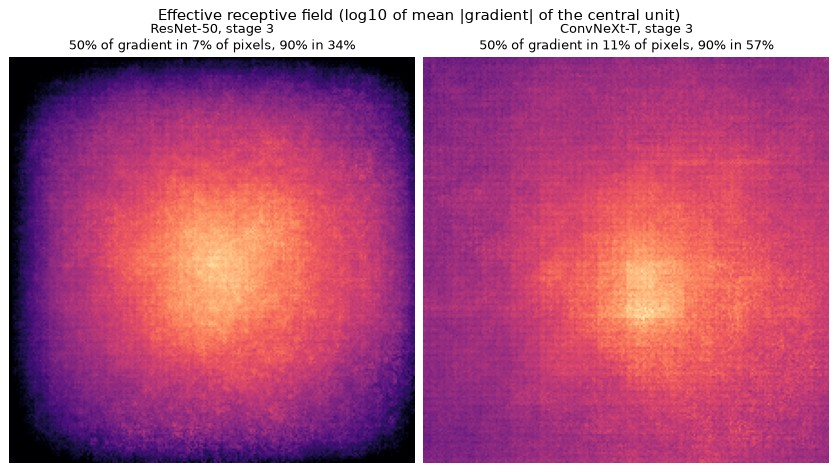

In [12]:
def effective_receptive_field(
    backbone: nn.Module, images: torch.Tensor
) -> torch.Tensor:
    # mean |gradient| of the central unit of the output feature map w.r.t. the input pixels, sums to 1
    x = images.clone().to(device).requires_grad_(True)
    out = backbone(x)
    h, w = out.shape[-2:]
    out[:, :, h // 2, w // 2].sum().backward()
    erf = x.grad.abs().sum(dim=(0, 1)).cpu()
    return erf / erf.sum()


def plot_erfs(erfs: dict[str, torch.Tensor]) -> None:
    # log scale with shared color limits, so that the extents of different ERFs are comparable
    logs = {name: torch.log10(erf + 1e-12) for name, erf in erfs.items()}
    vmax = max(log.max().item() for log in logs.values())
    fig, axes = plt.subplots(
        1, len(erfs), figsize=(4.6 * len(erfs), 5.2), layout="constrained"
    )
    for ax, (name, erf) in zip(axes, erfs.items()):
        ax.imshow(logs[name], cmap="magma", vmin=vmax - 4, vmax=vmax)
        # the smallest fraction of pixels that holds 50% (90%) of the total gradient
        cumsum = erf.flatten().sort(descending=True).values.cumsum(0)
        area50, area90 = [
            100 * ((cumsum < q).sum().item() + 1) / erf.numel() for q in (0.5, 0.9)
        ]
        ax.set_title(
            f"{name}\n50% of gradient in {area50:.0f}% of pixels, 90% in {area90:.0f}%",
            fontsize=10,
        )
        ax.axis("off")
    fig.suptitle(
        "Effective receptive field (log10 of mean |gradient| of the central unit)"
    )
    plt.show()


images = torch.stack([cub_test[i][0] for i in range(0, 1600, 100)])
backbones = {
    # stem + stages 1-3
    "ResNet-50, stage 3": nn.Sequential(*list(resnet.children())[:7]),
    # stem + stages 1-3 (with downsampling layers)
    "ConvNeXt-T, stage 3": convnext.features[:6],
}
erfs = {}
for name, backbone in backbones.items():
    erfs[name] = effective_receptive_field(backbone.to(device), images)
    backbone.cpu()
plot_erfs(erfs)

The ERF is much smaller than the theoretical RF and decays roughly like a Gaussian from the center: for ResNet-50, half of the influence comes from a small central area, and pixels near the border barely matter. ConvNeXt's ERF decays much more slowly and covers the whole image: large depthwise kernels let information travel further in the same number of layers.

### 1.5 Training recipe and normalization

#### Data augmentation

The ConvNeXt recipe uses strong augmentations. Every one of them encodes an **invariance** (the label does not change) and acts as a **regularizer** (the network never sees exactly the same image twice):

* **RandomResizedCrop** and **horizontal flip**: position, scale, mirror symmetry,
* **RandAugment**: 2 random operations (rotation, shear, color, contrast, ...) of a fixed strength,
* **Random Erasing**: occlusion, filled with random noise,
* **Mixup**: blend two images, and their labels in the same proportion,
* **CutMix**: paste a box from another image, labels proportional to the area.

All of them are available in [`torchvision.transforms.v2`](https://pytorch.org/vision/stable/transforms.html). Mixup and CutMix work on whole batches, since they need pairs of images.

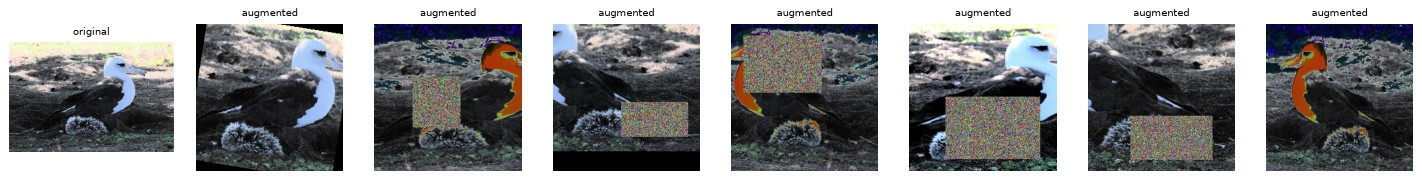

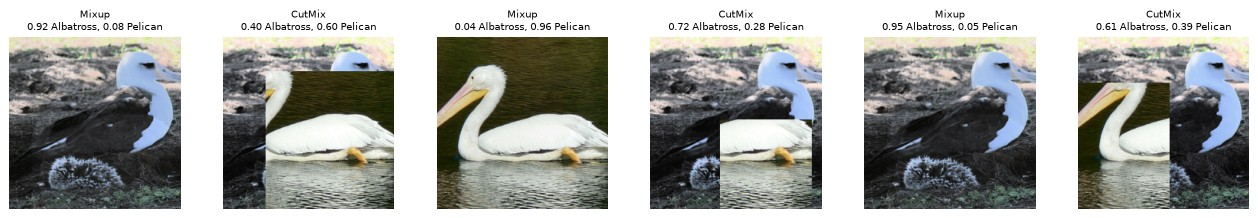

In [13]:
recipe_tf = T.Compose(
    [
        T.ToImage(),
        T.RandomResizedCrop(224, scale=(0.35, 1.0)),
        T.RandomHorizontalFlip(),
        T.RandAugment(num_ops=2, magnitude=9),
        T.ToDtype(torch.float32, scale=True),
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        T.RandomErasing(p=0.5, value="random"),
    ]
)
path, label = cub_train.samples[42]
original = Image.open(path).convert("RGB")
show_images(
    [original] + [recipe_tf(original) for _ in range(7)],
    ["original"] + ["augmented"] * 7,
    ncols=8,
    size=2.0,
)

# Mixup and CutMix mix every image of a batch with another one and return soft labels
pair_idx = [42, 3000]
images = torch.stack([cub_train[i][0] for i in pair_idx])
labels = torch.tensor([cub_train[i][1] for i in pair_idx])
mixup = T.MixUp(alpha=0.8, num_classes=len(bird_names))
cutmix = T.CutMix(alpha=1.0, num_classes=len(bird_names))
mixed, titles = [], []
for name, mix in [("Mixup", mixup), ("CutMix", cutmix)] * 3:
    x, y = mix(images, labels)
    mixed.append(x[0])
    weights = {bird_names[c].split()[-1]: y[0, c].item() for c in labels.tolist()}
    titles.append(f"{name}\n" + ", ".join(f"{w:.2f} {n}" for n, w in weights.items()))
show_images(mixed, titles, ncols=6, size=2.4)

#### Learning rate schedule and label smoothing

The old ResNet recipe used SGD with **step decay**: the learning rate is divided by 10 a few times during training. The ConvNeXt recipe uses AdamW with a **linear warmup** (stable start, when gradients are large and Adam's statistics are not estimated yet) and **cosine decay** (smoothly settle into a minimum). We will use the function below for training in Parts 2 and 3.

**Label smoothing** replaces the one-hot target with $1 - \varepsilon + \varepsilon / K$ for the correct class and $\varepsilon / K$ for the other $K - 1$ classes. With hard targets, cross-entropy keeps decreasing as the correct logit grows, so the network is pushed towards infinite confidence. With smoothing, the loss has a minimum at a finite logit, which penalizes overconfidence.

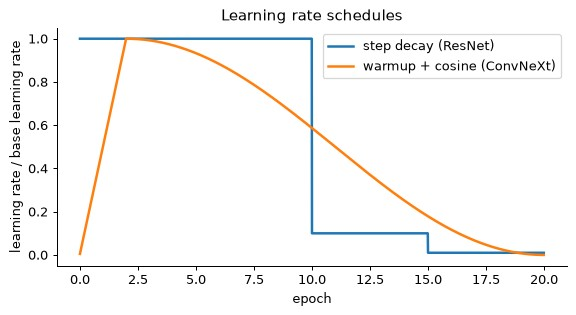

In [14]:
def lr_multiplier(
    step: int, total_steps: int, warmup_steps: int = 0, schedule: str = "cosine"
) -> float:
    # learning rate at a given optimizer step, relative to the base learning rate
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    if schedule == "step":  # divide by 10 at 50% and 75% of training
        return 0.1 ** sum(step >= m * total_steps for m in (0.5, 0.75))
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * progress))


fig, ax = plt.subplots(figsize=(6.5, 3.6))
steps_per_epoch, epochs = 100, 20
steps = np.arange(epochs * steps_per_epoch)
for schedule, warmup, label in [
    ("step", 0, "step decay (ResNet)"),
    ("cosine", 2, "warmup + cosine (ConvNeXt)"),
]:
    lr = [
        lr_multiplier(s, len(steps), warmup * steps_per_epoch, schedule) for s in steps
    ]
    ax.plot(steps / steps_per_epoch, lr, label=label, lw=2)
ax.set(
    xlabel="epoch",
    ylabel="learning rate / base learning rate",
    title="Learning rate schedules",
)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

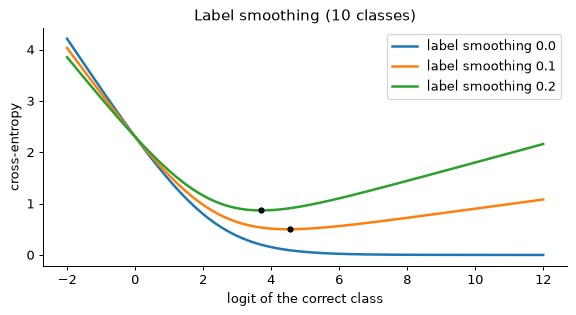

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
K, logits = 10, torch.linspace(-2, 12, 200)
batch = torch.zeros(len(logits), K)
batch[:, 0] = logits  # logit of the correct class (0), all other logits are 0
target = torch.zeros(len(logits), dtype=torch.long)
for eps in (0.0, 0.1, 0.2):
    loss = F.cross_entropy(batch, target, label_smoothing=eps, reduction="none")
    ax.plot(logits, loss, lw=2, label=f"label smoothing {eps}")
    if eps > 0:
        ax.plot(logits[loss.argmin()], loss.min(), "ko", ms=4)
ax.set(
    xlabel="logit of the correct class",
    ylabel="cross-entropy",
    title=f"Label smoothing ({K} classes)",
)
ax.legend()
plt.tight_layout()
plt.show()

#### BatchNorm vs LayerNorm

Both normalize to zero mean and unit variance and then apply a learned per-channel scale and shift, but over different axes of an `(N, C, H, W)` tensor:

* **BatchNorm** computes statistics of every channel over the batch and space, `(N, H, W)`. During training, the output for one image depends on the other images in the batch; at inference, it uses running averages collected during training instead, so it behaves differently in train and eval mode.
* **LayerNorm** in ConvNeXt computes statistics over the channels `C` of every pixel separately, exactly like a Transformer normalizes every token. Every image is processed independently, in the same way during training and inference.

In [16]:
from torchvision.models.convnext import LayerNorm2d as TorchvisionLayerNorm2d

bn, ln = nn.BatchNorm2d(16), TorchvisionLayerNorm2d(16)
x = torch.randn(8, 16, 7, 7)
x_other = x.clone()
x_other[1:] = (
    3 * torch.randn(7, 16, 7, 7) + 2
)  # the same first image, different rest of the batch

with torch.no_grad():
    bn.train()
    print("max change of the output for image 0, when the rest of the batch changes:")
    print(f"  BatchNorm (train mode): {(bn(x)[0] - bn(x_other)[0]).abs().max():.3f}")
    print(f"  LayerNorm:              {(ln(x)[0] - ln(x_other)[0]).abs().max():.3f}")
    bn.eval()
    print(f"  BatchNorm (eval mode):  {(bn(x)[0] - bn(x_other)[0]).abs().max():.3f}")

max change of the output for image 0, when the rest of the batch changes:
  BatchNorm (train mode): 2.778
  LayerNorm:              0.000
  BatchNorm (eval mode):  0.000


### 1.6 Pointwise 1x1 convolution = MLP

A 1x1 convolution does no spatial mixing: it is a linear layer `C_in -> C_out` applied to the channel vector of every pixel, with the same weights at every position. Two 1x1 convolutions with an activation between them are therefore a per-pixel MLP, like the MLP in a Transformer block. This is why `torchvision` can implement them with `nn.Linear`.

In [17]:
conv = nn.Conv2d(96, 384, kernel_size=1)
linear = nn.Linear(96, 384)
with torch.no_grad():
    linear.weight.copy_(conv.weight.view(384, 96))
    linear.bias.copy_(conv.bias)
    x = torch.randn(2, 96, 14, 14)
    y_conv = conv(x)
    # (N, C, H, W) -> (N, H, W, C) and back
    y_linear = linear(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)

print("same output:", torch.allclose(y_conv, y_linear, atol=1e-5))

same output: True


# Part 2: Using a pretrained ConvNeXt

A network pretrained on a large dataset is a general-purpose **feature extractor**. If we remove its classification head, every image becomes an **embedding**: here, the 768-dimensional vector after global average pooling. Images that look similar to the network get similar embeddings, which already allows search, visualization and classification with simple models. When this is not enough, we **fine-tune** the whole network on our data.

## 2.1 What does the ImageNet model already know?

ImageNet-1K contains 59 bird classes, but CUB has 200 species with different names, so we can expect sensible but coarse predictions.

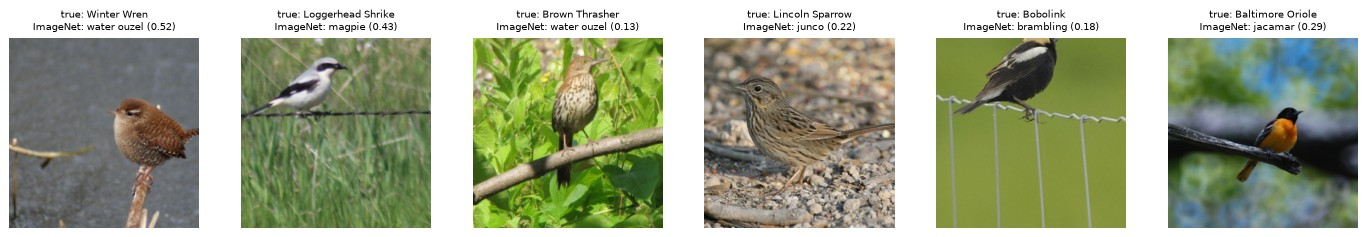

In [18]:
imagenet_classes = ConvNeXt_Tiny_Weights.IMAGENET1K_V1.meta["categories"]
convnext = convnext.to(device)

idx = np.random.choice(len(cub_test), 6, replace=False)
x = torch.stack([cub_test[i][0] for i in idx])
with torch.no_grad():
    probs = convnext(x.to(device)).softmax(dim=1).cpu()
top_p, top_i = probs.max(dim=1)
titles = [
    f"true: {bird_names[cub_test.targets[i]]}\nImageNet: {imagenet_classes[c]} ({p:.2f})"
    for i, c, p in zip(idx, top_i.tolist(), top_p.tolist())
]
show_images(list(x), titles, ncols=6, size=2.6)

## 2.2 Image embeddings

We replace the last linear layer (768 -> 1000 ImageNet classes) with `nn.Identity()`. What remains is the backbone, global average pooling and the final LayerNorm. We compute the embeddings of all images once, so that they can be reused. They will also persist if you need to restart the notebook.

In [19]:
CUB_EMBEDDING_BATCH_SIZE = 64


@torch.no_grad()
def extract_embeddings(model: nn.Module, dataset: Dataset) -> np.ndarray:
    loader = DataLoader(
        dataset,
        batch_size=CUB_EMBEDDING_BATCH_SIZE,
        num_workers=NUM_WORKERS,
    )
    model.eval()
    embeddings = []
    for x, _ in loader:
        with autocast():
            embeddings.append(model(x.to(device)).float().cpu())
    return torch.cat(embeddings).numpy()


embedder = convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
# keep LayerNorm2d + Flatten, drop Linear(768, 1000)
embedder.classifier[2] = nn.Identity()
embedder = embedder.to(device)

embeddings_path = os.path.join(DATA_ROOT, "cub_convnext_tiny_embeddings.npz")
if os.path.exists(embeddings_path):
    saved = np.load(embeddings_path)
    X_train, X_test = saved["X_train"], saved["X_test"]
else:
    start = time.time()
    X_train = extract_embeddings(embedder, cub_train)
    X_test = extract_embeddings(embedder, cub_test)
    np.savez(embeddings_path, X_train=X_train, X_test=X_test)
    print(f"embeddings computed in {time.time() - start:.0f} s")

y_train, y_test = np.array(cub_train.targets), np.array(cub_test.targets)
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

embeddings computed in 206 s
X_train: (5994, 768), X_test: (5794, 768)


## 2.3 Similarity search

To find images similar to a query image, we compare their embeddings with **cosine similarity**, which ignores vector length and looks only at the direction:

$$\cos(\mathbf{q}, \mathbf{x}) = \frac{\mathbf{q}^\top \mathbf{x}}{\lVert \mathbf{q} \rVert\, \lVert \mathbf{x} \rVert}$$

### Exercise 1: Similarity search

Implement `most_similar`, which returns the indices and cosine similarities of the `k` gallery embeddings most similar to the query, from the most similar one.

Hint: if you L2-normalize each row to be a unit vector, cosine similarity reduces to just a dot product, which is a matrix-vector product to compute one-to-many similarity. [`np.linalg.norm`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.norm.html) with `axis=1, keepdims=True` and [`np.argsort`](https://numpy.org/doc/stable/reference/generated/numpy.argsort.html) will be useful here.

In [20]:
def most_similar(
    query: np.ndarray, gallery: np.ndarray, k: int = 5
) -> tuple[np.ndarray, np.ndarray]:
    # query: (D,) array, gallery: (N, D) array
    # returns: indices (k,) and similarities (k,), most similar first
    ...


In [21]:
indices, similarities = most_similar(X_train[0], X_train, k=3)
assert indices.shape == (3,) and similarities.shape == (3,), (
    "return k indices and k similarities"
)
assert indices[0] == 0 and np.isclose(similarities[0], 1, atol=1e-4), (
    "the query itself should be the top match"
)
assert np.all(np.diff(similarities) <= 1e-6), "sort from the most similar"
indices_scaled, similarities_scaled = most_similar(5 * X_test[7], 0.1 * X_train, k=10)
indices_ref, similarities_ref = most_similar(X_test[7], X_train, k=10)
assert np.array_equal(indices_scaled, indices_ref), (
    "cosine similarity should not depend on vector lengths"
)
assert np.allclose(similarities_scaled, similarities_ref, atol=1e-4)
assert -1 <= similarities_ref.min() and similarities_ref.max() <= 1 + 1e-6, (
    "cosine similarity is in [-1, 1]"
)
print("OK")

TypeError: cannot unpack non-iterable NoneType object

Let's search the training set with a few test images. Green titles mark results of the same species as the query.

In [ ]:
def show_search(query_idx: int, k: int = 6) -> None:
    indices, similarities = most_similar(X_test[query_idx], X_train, k)
    fig, axes = plt.subplots(1, k + 1, figsize=(2.1 * (k + 1), 2.6))
    axes[0].imshow(denormalize(cub_test[query_idx][0]))
    axes[0].set_title(
        f"QUERY\n{bird_names[y_test[query_idx]]}", fontsize=8, weight="bold"
    )
    for ax, i, s in zip(axes[1:], indices, similarities):
        ax.imshow(denormalize(cub_train[i][0]))
        color = "green" if y_train[i] == y_test[query_idx] else "red"
        ax.set_title(
            f"{bird_names[y_train[i]]}\nsimilarity {s:.2f}", fontsize=8, color=color
        )
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


for query_idx in np.random.choice(len(X_test), 3, replace=False):
    show_search(query_idx)

A standard metric for retrieval is **precision@k**: the fraction of the top $k$ results that have the same class as the query, averaged over all queries. Note that for higher $k$, values fall, since the task gets harder (more chances to make a mistake).

In [ ]:
def precision_at_k(
    X_query: np.ndarray,
    y_query: np.ndarray,
    X_gallery: np.ndarray,
    y_gallery: np.ndarray,
    k: int,
) -> float:
    Q = X_query / np.linalg.norm(X_query, axis=1, keepdims=True)
    G = X_gallery / np.linalg.norm(X_gallery, axis=1, keepdims=True)
    top_k = np.argsort(-(Q @ G.T), axis=1)[:, :k]
    return (y_gallery[top_k] == y_query[:, None]).mean()


for k in (1, 5, 10):
    precision = precision_at_k(X_test, y_test, X_train, y_train, k)
    print(
        f"precision@{k:<2d}: {100 * precision:.1f}% (random: {100 / len(bird_names):.1f}%)"
    )

## 2.4 Visualizing the embedding space

[t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) maps high-dimensional points to 2D, trying to keep neighbours close (an alternative is [UMAP](https://umap-learn.readthedocs.io/)). The network never saw these 200 species, yet many of them form clusters.

200 colors would be unreadable, so we color birds by group, using the last word of the species name (e.g. all 25 warblers or 21 sparrows), showing the 10 largest groups and the rest in gray. Related species lie close together. This is an example of successful **representation learning** - neural network learning representation of semantic concepts in a vector space.

In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


def tsne_2d(X: np.ndarray) -> np.ndarray:
    # PCA to 50 dimensions first is standard: it is faster and removes noise
    X = PCA(n_components=50, random_state=0).fit_transform(
        X / np.linalg.norm(X, axis=1, keepdims=True)
    )
    return TSNE(n_components=2, init="pca", random_state=0).fit_transform(X)


# "Black throated Blue Warbler" -> "Warbler"
groups = np.array([bird_names[c].split()[-1] for c in range(len(bird_names))])
group_names, group_counts = np.unique(groups, return_counts=True)
top_groups = group_names[np.argsort(-group_counts)][:10]


def plot_groups(ax: plt.Axes, xy: np.ndarray, y: np.ndarray, title: str) -> None:
    ax.scatter(*xy.T, s=3, c="lightgray")
    colors = plt.get_cmap("tab10").colors
    for color, group in zip(colors, top_groups):
        mask = groups[y] == group
        ax.scatter(
            *xy[mask].T, s=3, color=color, label=f"{group} ({(groups == group).sum()})"
        )
    ax.set_title(title)
    ax.axis("off")


xy_test = tsne_2d(X_test)
fig, ax = plt.subplots(figsize=(9, 7))
plot_groups(
    ax,
    xy_test,
    y_test,
    "t-SNE of ConvNeXt-T embeddings (test set), colored by bird group",
)
ax.legend(
    markerscale=4, loc="center left", bbox_to_anchor=(1, 0.5), title="group (species)"
)
plt.tight_layout()
plt.show()

## 2.5 Linear probing: images as a table

Embeddings turn an image dataset into a **tabular** dataset: one row per image, 768 numeric features and a label. From here on, any classical machine learning model works, e.g. from scikit-learn. A linear classifier trained on frozen embeddings is called a **linear probe**. It is cheap, needs little data, and it is the standard way to measure how good a representation is. The general technique of training any classifier on top of embeddings is often called *linear probing*, even when it's not necessarily a linear model.

### Exercise 2: Linear probing
1. Complete `make_linear_probe`, which should return an (unfitted) scikit-learn [pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html): [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) followed by [`LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Use `max_iter=1000` and `C=0.05`. 
2. Train the probe on `X_train` and compute its test accuracy, `probe_accuracy`.
3. For comparison, train a [`KNeighborsClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html) with `n_neighbors=10`, cosine distance and distance weighting, and compute its test accuracy, `knn_accuracy`. Use `n_jobs=-1` for speed.

Note that in real project you would use cross-validation to select a `C` value, here we pre-calculated a reasonable value.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler


def make_linear_probe() -> Pipeline:
    ...


probe = ...
probe_accuracy = ...

knn = ...
knn_accuracy = ...
print(f"linear probe: {100 * probe_accuracy:.1f}%, kNN: {100 * knn_accuracy:.1f}%")


In [ ]:
assert isinstance(probe_accuracy, float) and isinstance(knn_accuracy, float)
assert probe_accuracy > 0.6, (
    f"linear probe accuracy should be above 60%, got {100 * probe_accuracy:.1f}%"
)
assert knn_accuracy > 0.5, (
    f"kNN accuracy should be above 50%, got {100 * knn_accuracy:.1f}%"
)
assert len(make_linear_probe().steps) == 2, (
    "the pipeline should have 2 steps: scaler and logistic regression"
)
print("OK")

### How many labels do we need?

Since we only train a linear model on fixed features, the probe works with very little data. Let's train it on 1 to 30 labelled images per species.

In [ ]:
# with 1 image per species, scikit-learn warns that there are many classes for few samples
warnings.filterwarnings("ignore", message="The number of unique classes")

rng = np.random.default_rng(0)

shots, few_shot_accuracy = [1, 2, 5, 10, 30], []
for n in shots:
    # n random training images of every species
    subset = np.concatenate(
        [
            rng.permutation(np.flatnonzero(y_train == c))[:n]
            for c in range(len(bird_names))
        ]
    )
    model = make_linear_probe().fit(X_train[subset], y_train[subset])
    few_shot_accuracy.append(model.score(X_test, y_test))
    print(
        f"{n:2d} images per species ({len(subset):4d} in total): {100 * few_shot_accuracy[-1]:.1f}%"
    )

plt.figure(figsize=(6, 3.5))
plt.semilogx(shots, 100 * np.array(few_shot_accuracy), "o-", lw=2)
plt.xticks(shots, shots)
plt.xlabel("labelled training images per species")
plt.ylabel("test accuracy (%)")
plt.title("Linear probe on frozen ConvNeXt-T embeddings")
plt.show()

## 2.6 Fine-tuning

A linear probe cannot change the features, relying only on representation learning and pretrained features.

In **fine-tuning**, we replace the head with a new linear layer for our 200 classes and train the whole network. Below is a small training engine, which we will also use in Part 3. It trains with mixed precision, the warmup + cosine schedule from Part 1, AdamW (or SGD) and label smoothing, and evaluates after every epoch.

For fine-tuning, we use **two learning rates**: a small one for the pretrained backbone, so that we only adjust its features instead of destroying them, and a 10x larger one for the new, randomly initialized head. We also use light data augmentation.

In [ ]:
def make_param_groups(
    model: nn.Module,
    lr: float,
    weight_decay: float,
    head: nn.Module | None = None,
    head_lr: float | None = None,
) -> list[dict]:
    # no weight decay for biases and normalization parameters (1D tensors), optionally a separate head lr
    head_params = {id(p) for p in head.parameters()} if head is not None else set()
    groups = {}
    for p in model.parameters():
        is_head, no_decay = id(p) in head_params, p.ndim <= 1
        groups.setdefault((is_head, no_decay), []).append(p)
    return [
        {
            "params": params,
            "lr": head_lr if is_head else lr,
            "weight_decay": 0.0 if no_decay else weight_decay,
        }
        for (is_head, no_decay), params in groups.items()
    ]


@torch.no_grad()
def evaluate(model: nn.Module, loader: DataLoader) -> float:
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x = prepare_images(x.to(device, non_blocking=True))
        x = x.to(memory_format=MEMORY_FORMAT)
        with autocast():
            correct += (model(x).argmax(dim=1).cpu() == y).sum().item()
        total += len(y)
    return correct / total


def fit(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    epochs: int,
    *,
    optimizer: str = "adamw",
    lr: float = 1e-3,
    weight_decay: float = 0.05,
    schedule: str = "cosine",
    warmup_epochs: int = 0,
    label_smoothing: float = 0.0,
    batch_transform: Callable | None = None,
    head: nn.Module | None = None,
    head_lr: float | None = None,
) -> dict[str, list[float]]:
    # faster convolutions on GPUs
    model = model.to(device).to(memory_format=MEMORY_FORMAT)

    groups = make_param_groups(model, lr, weight_decay, head, head_lr)

    if optimizer == "adamw":
        opt = torch.optim.AdamW(groups)
    else:
        opt = torch.optim.SGD(groups, momentum=0.9, nesterov=True)

    total_steps, warmup_steps = (
        epochs * len(train_loader),
        warmup_epochs * len(train_loader),
    )
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda step: lr_multiplier(step, total_steps, warmup_steps, schedule)
    )
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    # scales the loss to avoid float16 underflow
    scaler = torch.amp.GradScaler(enabled=USE_AMP)

    history = {"train_loss": [], "val_accuracy": [], "epoch_time": []}
    for epoch in range(1, epochs + 1):
        start = time.time()
        model.train()
        loss_sum, num_samples = 0.0, 0
        for x, y in train_loader:
            # uint8 images are converted to normalized floats on the GPU
            x = prepare_images(x.to(device, non_blocking=True))
            x = x.to(memory_format=MEMORY_FORMAT)
            y = y.to(device, non_blocking=True)

            # e.g. Mixup / CutMix, which make soft labels
            if batch_transform is not None:
                x, y = batch_transform(x, y)

            with autocast():
                loss = criterion(model(x), y)

            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            scheduler.step()
            loss_sum += loss.item() * len(x)
            num_samples += len(x)
        history["train_loss"].append(loss_sum / num_samples)
        history["val_accuracy"].append(evaluate(model, val_loader))
        history["epoch_time"].append(time.time() - start)
        print(
            f"epoch {epoch:2d}/{epochs} | train loss {history['train_loss'][-1]:.3f} | "
            f"val accuracy {100 * history['val_accuracy'][-1]:.1f}% | {time.time() - start:.0f} s"
        )
    return history

In [ ]:
FINETUNE_EPOCHS = 5
CUB_FINETUNING_BATCH_SIZE = 64

finetune_tf = T.Compose(
    [
        T.ToImage(),
        T.RandomResizedCrop(224, scale=(0.35, 1.0)),
        T.RandomHorizontalFlip(),
        T.ToDtype(torch.float32, scale=True),
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)
cub_train_aug = CUB200(DATA_ROOT, train=True, transform=finetune_tf)
loader_kwargs = dict(
    batch_size=CUB_FINETUNING_BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=device.type == "cuda",
)
cub_train_loader = DataLoader(
    cub_train_aug, shuffle=True, drop_last=True, **loader_kwargs
)
cub_test_loader = DataLoader(cub_test, **loader_kwargs)

seed_everything(0)
finetuned = convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1)

# new head for 200 species
finetuned.classifier[2] = nn.Linear(768, len(bird_names))

history = fit(
    finetuned,
    cub_train_loader,
    cub_test_loader,
    FINETUNE_EPOCHS,
    lr=1e-4,
    head=finetuned.classifier,
    head_lr=1e-3,
    weight_decay=0.05,
    warmup_epochs=1,
    label_smoothing=0.1,
)
finetune_accuracy = history["val_accuracy"][-1]

In [ ]:
results = {
    "kNN": knn_accuracy,
    "linear probe": probe_accuracy,
    "fine-tuning": finetune_accuracy,
}
plt.figure(figsize=(7, 2.4))
bars = plt.barh(
    list(results)[::-1],
    [100 * a for a in list(results.values())[::-1]],
    color="#7d6cc4",
)
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.xlim(0, 100)
plt.xlabel("test accuracy (%)")
plt.title("ConvNeXt-T on CUB-200-2011")
plt.show()

Fine-tuning usually wins clearly on CUB: species differ in small details that ImageNet features were not trained to separate. On datasets closer to ImageNet, or with very few labels, the gap is smaller and frozen embeddings are often good enough, at a fraction of the cost. In other areas than vision, e.g. in NLP or for molecular graphs, this technique can be very successful for small datasets.

### The embedding space after fine-tuning

Fine-tuning changed the features themselves, not only the classifier. Let's look at the embeddings of the fine-tuned network again: the species clusters should be much tighter, and similarity search more precise.

In [ ]:
finetuned.classifier[2] = nn.Identity()
X_train_ft = extract_embeddings(finetuned, cub_train)
X_test_ft = extract_embeddings(finetuned, cub_test)
for k in (1, 5):
    before = precision_at_k(X_test, y_test, X_train, y_train, k)
    after = precision_at_k(X_test_ft, y_test, X_train_ft, y_train, k)
    print(
        f"precision@{k}: {100 * before:.1f}% pretrained -> {100 * after:.1f}% fine-tuned"
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
plot_groups(axes[0], xy_test, y_test, "pretrained ConvNeXt-T")
plot_groups(axes[1], tsne_2d(X_test_ft), y_test, "fine-tuned on CUB")
axes[1].legend(markerscale=4, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

In [ ]:
# free the GPU memory before Part 3
del resnet, convnext, embedder, finetuned
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Part 3: From ResNet to ConvNeXt

Now we follow the ConvNeXt paper ourselves, at a scale that fits in a lab: networks with about 4-5M parameters, trained from scratch for 20 epochs. We start from a small ResNet and apply the modernization steps one by one, keeping the compute roughly constant, as the paper does. In every step, you implement a new building block (or assemble blocks into a model), check it, and train the resulting network with a given training loop.

| Step | Change | Paper: ImageNet top-1, GFLOPs | You implement |
|---|---|---|---|
| 1 | small ResNet, "old" training recipe | 76.1, 4.1 | Exercises 3-6: shortcut, bottleneck block, stem, ResNet |
| 2 | modern training recipe | 78.8, 4.1 | |
| 3 | stage compute ratio | 79.4, 4.5 | |
| 4 | patchify stem | 79.5, 4.4 | Exercise 7: patchify stem |
| 5 | depthwise convolution, wider network | 80.5, 5.3 | Exercise 8: ResNeXt block |
| 6 | inverted bottleneck | 80.6, 4.6 | Exercise 9: inverted bottleneck |
| 7 | depthwise convolution moved up, larger kernel | 80.6, 4.2 | Exercise 10: large kernel block |
| 8 | GELU, fewer activations and normalizations | 81.4, 4.2 | Exercise 11: micro design block |
| 9 | separate downsampling layers, stochastic depth | 82.0, 4.5 | Exercises 12-14: downsampling layer, ConvNeXt block, ConvNeXt |

**Dataset.** Training from scratch needs many more images per class than CUB has. We use [Imagenette](https://github.com/fastai/imagenette): 10 easy-to-distinguish ImageNet classes, with 9469 training and 3925 validation images. Its classes come from ImageNet, so it should simulate the real pretraining well.

**What to expect.** Our networks, dataset and training are tiny compared to the paper (300 epochs on 1.28M images), so not every step will help. The training recipe gives by far the largest gain, and among the architecture changes, the depthwise convolutions with a wider network and the inverted bottleneck help the most. Some changes trade a bit of accuracy for a faster network, and some, like large kernels, pay off mainly with more data and longer training. Also, two runs that differ only in the random seed can differ noticeably here, so look at the overall trend rather than single steps.

## Settings, data, and training tools

### Choosing the image size

By default, we train on 224x224 images, like ConvNeXt on ImageNet. If your hardware is weaker (a slower GPU, or no GPU at all), use 128x128 images. Training will be about 3x faster, and accuracy is a few percent lower, but the conclusions are similar.

**Macs with Apple Silicon.** PyTorch uses the Mac's GPU through the MPS backend, but without mixed precision, so training will be quite a bit slower. You can live with that, use smaller images, or switch to Google Colab.

Without a GPU, training is a bit slow: about 3 minutes per epoch at 128x128 on 4 CPU cores, i.e. over 8 hours for all steps. This is doable, but you can use smaller images, or Google Colab with T4 GPU.

Whichever you choose, use the same settings for all steps, so that the results are comparable.

In [ ]:
IMG_SIZE = 224  # 224 or 128
EPOCHS = 20  # 20 is the default, longer = better results typically
BATCH_SIZE = 128

### Data

Decoding JPEG files and augmenting images on the CPU can be slower than training these small networks on a GPU. So we decode all images once and keep them in memory as `uint8` tensors: training images resized and center-cropped to a square slightly larger than `IMG_SIZE` (256x256 for 224), validation images resized and center-cropped to `IMG_SIZE`, as for ImageNet models.

Random augmentations are applied on the fly to the `uint8` images by `DataLoader` workers, and the conversion to normalized floats is done on the GPU (in `fit`), so that the CPU has less work. The dataset code is in `datasets.py`.

In [ ]:
from datasets import IMAGENETTE_CLASSES, TensorImageDataset, load_imagenette

start = time.time()
# training images: a square slightly larger than IMG_SIZE (256 for 224), as for ImageNet models
stored_size = round(IMG_SIZE / 0.875)
train_tf = T.Compose([T.Resize(stored_size), T.CenterCrop(stored_size)])
val_tf = T.Compose([T.Resize(stored_size), T.CenterCrop(IMG_SIZE)])
train_images, train_labels = load_imagenette(
    DATA_ROOT, "train", IMG_SIZE, train_tf, NUM_WORKERS
)
val_images, val_labels = load_imagenette(
    DATA_ROOT, "val", IMG_SIZE, val_tf, NUM_WORKERS
)
num_bytes = train_images.numel() + val_images.numel()
print(
    f"Imagenette: {len(train_labels)} train / {len(val_labels)} val images, "
    f"{num_bytes / 2**30:.1f} GB, decoded in {time.time() - start:.0f} s"
)

# augmentations of uint8 images; fit() converts them to normalized floats on the GPU
old_train_tf = T.Compose(
    [T.RandomResizedCrop(IMG_SIZE, scale=(0.35, 1.0)), T.RandomHorizontalFlip()]
)
modern_train_tf = T.Compose(
    [
        T.RandomResizedCrop(IMG_SIZE, scale=(0.35, 1.0)),
        T.RandomHorizontalFlip(),
        T.RandAugment(num_ops=2, magnitude=5),
    ]
)

loader_kwargs = dict(
    num_workers=NUM_WORKERS,
    pin_memory=device.type == "cuda",
    persistent_workers=NUM_WORKERS > 0,
)
old_train_loader = DataLoader(
    TensorImageDataset(train_images, train_labels, old_train_tf),
    batch_size=BATCH_SIZE, shuffle=True, drop_last=True, **loader_kwargs,
)  # fmt: skip
modern_train_loader = DataLoader(
    TensorImageDataset(train_images, train_labels, modern_train_tf),
    batch_size=BATCH_SIZE, shuffle=True, drop_last=True, **loader_kwargs,
)  # fmt: skip
val_loader = DataLoader(
    TensorImageDataset(val_images, val_labels, T.Identity()),
    batch_size=256,
    **loader_kwargs,
)

idx = np.random.choice(len(train_labels), 6, replace=False)
show_images(
    [old_train_loader.dataset[i][0] for i in idx]
    + [modern_train_loader.dataset[i][0] for i in idx],
    [f"old: {IMAGENETTE_CLASSES[train_labels[i]]}" for i in idx]
    + [f"modern: {IMAGENETTE_CLASSES[train_labels[i]]}" for i in idx],
    suptitle="Training images with the old and the modern augmentation",
)

### Training recipes

Both recipes use the `fit` function from Part 2. The table compares them with the recipes in the papers:

| | old: ResNet (2015) | modern: ConvNeXt (2022) |
|---|---|---|
| optimizer | SGD with momentum | AdamW |
| learning rate schedule | step decay | linear warmup + cosine decay |
| augmentation | random resized crop, flip | + RandAugment (+ Random Erasing, Mixup, CutMix) |
| regularization | weight decay | weight decay, label smoothing (+ stochastic depth, Layer Scale, EMA) |
| epochs | 90 | 300 |

Ingredients in brackets are omitted at our scale, except for stochastic depth, which we add to the ConvNeXt block in step 9. Strong augmentation regularizes a lot and improves the model, but only at scale, i.e. with large enough model, data, and long training. With out 20 epochs, the full ConvNeXt augmentation lowers the accuracy. So we use a mild RandAugment (2 operations of magnitude 5 out of 31), which starts to help with longer training.

`train_step` function:
- trains a model built by `make_model`
- prints its size
- records the results
- plots the accuracy of all steps so far, similarly to the figure in the paper

Next to the accuracy, it also shows the cost of every network: parameters, GMACs and training time per epoch. Watch all of them: some steps trade a bit of accuracy for a faster network, and GMACs do not always predict the actual time. The results are also saved to a file, so they survive a restart of the notebook.

The training time is measured for the network alone: before training, `measure_speed` runs a few training steps (forward pass, backward pass, optimizer step) on a random batch and computes the speed in images per second. The time per epoch printed during training can be longer, because it also includes evaluation and data loading. On a machine with few CPU cores (e.g. 2 on Google Colab), data loading can become the bottleneck, and then all networks seem equally fast.

In [ ]:
import json

RECIPES = {
    "old": dict(
        train_loader=old_train_loader,
        optimizer="sgd",
        lr=0.05,
        weight_decay=5e-4,
        schedule="step",
    ),
    "modern": dict(
        train_loader=modern_train_loader,
        optimizer="adamw",
        lr=2e-3,
        weight_decay=0.05,
        schedule="cosine",
        warmup_epochs=2,
        label_smoothing=0.1,
    ),
}
RESULTS_PATH = os.path.join(DATA_ROOT, f"convnext_steps_results_{IMG_SIZE}px.json")
results = {}
if os.path.exists(RESULTS_PATH):
    with open(RESULTS_PATH) as f:
        results = json.load(f)
    print(f"loaded results of {len(results)} steps from {RESULTS_PATH}")


def synchronize() -> None:
    # wait until the GPU finishes all queued work, needed for correct timing
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def measure_speed(model: nn.Module, steps: int = 10, warmup: int = 3) -> float:
    # training speed of the network alone, in images per second: forward pass, backward pass
    # and optimizer step on a random batch, without data loading (which depends on the CPU)
    model = copy.deepcopy(model).to(device).to(memory_format=MEMORY_FORMAT).train()
    optimizer = torch.optim.AdamW(model.parameters())
    x = torch.randn(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE, device=device)
    x = x.to(memory_format=MEMORY_FORMAT)
    y = torch.randint(0, 10, (BATCH_SIZE,), device=device)
    for i in range(warmup + steps):
        if (
            i == warmup
        ):  # the first steps are slower (memory allocation, algorithm selection)
            synchronize()
            start = time.time()
        with autocast():
            loss = F.cross_entropy(model(x), y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
    synchronize()
    return steps * BATCH_SIZE / (time.time() - start)


def train_step(
    name: str,
    make_model: Callable[[], nn.Module],
    recipe: str = "modern",
    epochs: int = EPOCHS,
) -> None:
    seed_everything(0)
    model = make_model()
    params, gmacs = count_params(model) / 1e6, count_gmacs(model, IMG_SIZE)
    speed = measure_speed(model)
    print(
        f"{name}: {params:.2f}M parameters, {gmacs:.3f} GMACs, "
        f"training speed {speed:.0f} images/s, recipe '{recipe}', {epochs} epochs"
    )
    config = dict(RECIPES[recipe])
    history = fit(model, config.pop("train_loader"), val_loader, epochs, **config)
    results[name] = dict(
        accuracy=history["val_accuracy"][-1],
        params=params,
        gmacs=gmacs,
        # time per epoch of the network alone, without data loading and evaluation
        train_time=len(train_labels) / speed,
        # measured time per epoch (median over epochs), including data loading and evaluation
        epoch_time=float(np.median(history["epoch_time"])),
        history=history,
    )
    with open(RESULTS_PATH, "w") as f:
        json.dump(results, f)
    compare_with_previous(name)
    plot_results()


def compare_with_previous(name: str) -> None:
    # accuracy and cost of a step, relative to the step trained before it
    names = list(results)
    i = names.index(name)
    if i == 0:
        return
    new, old = results[name], results[names[i - 1]]
    print(
        f"\ncompared with '{names[i - 1]}': "
        f"accuracy {100 * (new['accuracy'] - old['accuracy']):+.1f} points, "
        f"parameters {100 * (new['params'] / old['params'] - 1):+.0f}%, "
        f"GMACs {100 * (new['gmacs'] / old['gmacs'] - 1):+.0f}%, "
        f"training time {100 * (new['train_time'] / old['train_time'] - 1):+.0f}%"
    )


def plot_results() -> None:
    names = list(results)
    accuracy = [100 * results[n]["accuracy"] for n in names]
    fig, ax = plt.subplots(figsize=(9, 0.4 * len(names) + 1))
    bars = ax.barh(names, accuracy, color="#7d6cc4")
    labels = [
        f"{a:.1f}%  ({results[n]['params']:.1f}M params, {results[n]['gmacs']:.2f} GMACs, "
        f"{results[n]['train_time']:.0f} s/epoch)"
        for n, a in zip(names, accuracy)
    ]
    ax.bar_label(bars, labels, padding=4, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(max(0, min(accuracy) - 15), 115)  # room for the labels
    ax.set_xticks([t for t in ax.get_xticks() if t <= 100])
    ax.set_xlabel("Imagenette validation accuracy (%)")
    plt.tight_layout()
    plt.show()


def check_block(
    block: nn.Module,
    in_dim: int,
    out_dim: int,
    stride: int,
    num_params: int | None = None,
) -> None:
    # shape contract of all blocks: (N, in_dim, H, W) -> (N, out_dim, H / stride, W / stride)
    x = torch.randn(2, in_dim, 16, 16)
    y = block(x)
    expected = (2, out_dim, 16 // stride, 16 // stride)
    assert tuple(y.shape) == expected, (
        f"expected output shape {expected}, got {tuple(y.shape)}"
    )
    if num_params is not None:
        got = count_params(block)
        assert got == num_params, f"expected {num_params} parameters, got {got}"
    print(
        f"{type(block).__name__}({in_dim}, {out_dim}, stride={stride}): OK, {count_params(block)} parameters"
    )

## Step 1: ResNet

The first network is a small ResNet. We build it from the bottom up: the shortcut, the bottleneck block, the stem, and finally the whole network.

### Exercise 3: Projection shortcut

A residual block computes `branch(x) + shortcut(x)`, so both terms must have the same shape. There are two cases:

1. **Identity:** block keeps the shape of its input: stride 1, and the same number of input and output channels. `x` is added unchanged.

2.  **Projection shortcut:** The block changes the shape: stride 2 halves the resolution, or the number of channels changes. This happens in the first block of every stage. Then `x` must be transformed to the output shape by a 1x1 convolution with the block's stride, followed by BatchNorm.

The function `make_shortcut` chooses between the two cases.

Implement `ProjectionShortcut`:
- 1x1 convolution from `in_dim` to `out_dim` channels with stride `stride`
- BatchNorm

A convolution followed by BatchNorm does not need a bias (`bias=False`), since BatchNorm subtracts the mean anyway.

Useful: [`nn.Conv2d`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [`nn.BatchNorm2d`](https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html).

In [ ]:
class ProjectionShortcut(nn.Module):
    def __init__(self, in_dim: int, out_dim: int, stride: int) -> None:
        super().__init__()
        self.conv = ...
        self.bn = ...

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        ...


def make_shortcut(in_dim: int, out_dim: int, stride: int) -> nn.Module:
    # the block keeps the shape of its input: add the input unchanged
    if stride == 1 and in_dim == out_dim:
        return nn.Identity()

    # the block changes the shape: transform the input to the output shape
    return ProjectionShortcut(in_dim, out_dim, stride)


In [ ]:
shortcut = ProjectionShortcut(64, 128, stride=2)

assert shortcut(torch.randn(2, 64, 16, 16)).shape == (2, 128, 8, 8), (
    "wrong output shape"
)
assert count_params(shortcut) == 64 * 128 + 2 * 128, "1x1 conv without bias + BatchNorm"
assert isinstance(make_shortcut(64, 64, stride=1), nn.Identity)

print("OK")

### Exercise 4: Bottleneck block

Implement the ResNet [bottleneck block](https://arxiv.org/abs/1512.03385), in its common "v1.5" variant (stride in the 3x3 convolution):

```
x -> 1x1 conv (in_dim -> mid) -> BN -> ReLU
  -> 3x3 conv (mid -> mid, stride, padding 1) -> BN -> ReLU
  -> 1x1 conv (mid -> out_dim) -> BN
  -> + shortcut(x) -> ReLU
```

The bottleneck is 4x narrower than the block output, `mid = out_dim // 4`. All convolutions are followed by BatchNorm, so they don't need a bias.

Useful: [`F.relu`](https://pytorch.org/docs/stable/generated/torch.nn.functional.relu.html).

In [ ]:
class ResNetBottleneck(nn.Module):
    def __init__(self, in_dim: int, out_dim: int, stride: int = 1) -> None:
        super().__init__()
        mid = out_dim // 4
        self.conv1 = ...
        self.bn1 = ...
        self.conv2 = ...
        self.bn2 = ...
        self.conv3 = ...
        self.bn3 = ...
        self.shortcut = make_shortcut(in_dim, out_dim, stride)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        ...


In [ ]:
check_block(ResNetBottleneck(256, 256), 256, 256, stride=1, num_params=70400)
check_block(ResNetBottleneck(128, 256, stride=2), 128, 256, stride=2, num_params=95488)

# with the residual branch switched off (last BN scaled to 0), the block should compute ReLU(x)
block = ResNetBottleneck(64, 64).eval()

nn.init.zeros_(block.bn3.weight)
x = torch.randn(2, 64, 8, 8)
assert torch.allclose(block(x), F.relu(x)), (
    "check the shortcut connection and the final ReLU"
)

print("OK")

### Exercise 5: ResNet stem

The stem downsamples the image 4x before the first stage, with overlapping windows:

```
x -> 7x7 conv (3 -> out_dim, stride 2, padding 3) -> BN -> ReLU
  -> 3x3 max pooling (stride 2, padding 1)
```

Useful: [`nn.MaxPool2d`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html).

In [ ]:
class ResNetStem(nn.Module):
    def __init__(self, out_dim: int) -> None:
        super().__init__()
        self.conv = ...
        self.bn = ...
        self.pool = ...

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        ...


In [ ]:
stem = ResNetStem(32)

assert stem(torch.randn(2, 3, 128, 128)).shape == (2, 32, 32, 32), (
    "the stem should downsample 4x"
)
assert count_params(stem) == 3 * 7 * 7 * 32 + 2 * 32, (
    "7x7 conv without bias + BatchNorm"
)

print("OK")

### Exercise 6: ResNet

Now assemble the blocks into a network: stem, 4 stages of blocks, global average pooling and a linear classifier. The arguments are:

* `block`: the block class, called as `block(in_dim, out_dim, stride=...)`; we will plug in different blocks in the next steps
* `depths`: the number of blocks in each stage, e.g. `(2, 3, 4, 2)`
* `dims`: the output channels of each stage, e.g. `(128, 256, 512, 1024)`
* `stem_dim`: the output channels of the stem
* `stem`: the stem class, called as `stem(stem_dim)`

The first block of every stage changes the number of channels to `dims[i]`. The first block of stages 2, 3 and 4 also downsamples with `stride=2`; all other blocks have `stride=1`. The `forward` method applies the stem, the stages, global average pooling (the mean over H and W) and the head.

In [ ]:
class ResNet(nn.Module):
    def __init__(
        self,
        block: Callable[..., nn.Module],
        depths: tuple[int, ...],
        dims: tuple[int, ...],
        stem_dim: int,
        stem: Callable[[int], nn.Module] = ResNetStem,
        num_classes: int = 10,
    ) -> None:
        super().__init__()
        self.stem = stem(stem_dim)
        stages = []
        in_dim = stem_dim  # input channels of the next block
        # for every stage, append an nn.Sequential of its blocks to stages
        ...
        self.stages = nn.Sequential(*stages)
        self.head = ...

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        ...


In [ ]:
model = ResNet(
    ResNetBottleneck, depths=(2, 3, 4, 2), dims=(128, 256, 512, 1024), stem_dim=32
)

assert [len(stage) for stage in model.stages] == [2, 3, 4, 2], "wrong number of blocks"

x = model.stem(torch.randn(2, 3, IMG_SIZE, IMG_SIZE))
for i, (stage, dim) in enumerate(zip(model.stages, (128, 256, 512, 1024))):
    x = stage(x)
    size = IMG_SIZE // 4 // 2**i  # the stem downsamples 4x, every next stage 2x
    assert tuple(x.shape) == (2, dim, size, size), (
        f"expected {(2, dim, size, size)}, got {tuple(x.shape)}"
    )

assert model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE)).shape == (2, 10), (
    "the output should be (batch size, 10)"
)
assert count_params(model) == 4137386, (
    f"expected 4137386 parameters, got {count_params(model)}"
)

print("OK")

Our baseline is a ResNet with `(2, 3, 4, 2)` bottleneck blocks and stage widths `(128, 256, 512, 1024)`: ResNet-50's design at half the width and about 2/3 of the depth. We train it with the old recipe first.

In [ ]:
RESNET_DEPTHS = (2, 3, 4, 2)
RESNET_DIMS = (128, 256, 512, 1024)  # bottleneck widths: 32, 64, 128, 256


def make_model() -> nn.Module:
    return ResNet(ResNetBottleneck, RESNET_DEPTHS, RESNET_DIMS, stem_dim=32)


train_step("1. ResNet, old recipe", make_model, recipe="old")

## Step 2: Modern training recipe

The same network, trained with the modern recipe described above, only the training changes. Compare the training loss and the validation accuracy with step 1.

In [ ]:
train_step("2. modern recipe", make_model)

## Step 3: Stage compute ratio

ResNet-50 has `(3, 4, 6, 3)` blocks per stage. Swin Transformer uses a `1:1:3:1` ratio, and ConvNeXt copies it as `(3, 3, 9, 3)`, which moves compute into stage 3. Since every stage halves the resolution and doubles the channels, a block costs about the same in every stage, so the number of blocks directly sets the compute ratio. Stage 3 is the sweet spot for large number of blocks: early stages see only low-level patterns, while stage 4 has many channels and costly blocks.

We use the same `1:1:3:1` ratio with `(2, 2, 6, 2)` blocks: one block more than our baseline, just like the paper goes from 16 to 18 blocks. The extra block costs a little more compute.

In [ ]:
STAGE_RATIO_DEPTHS = (2, 2, 6, 2)


def make_model() -> nn.Module:
    return ResNet(ResNetBottleneck, STAGE_RATIO_DEPTHS, RESNET_DIMS, stem_dim=32)


train_step("3. stage ratio", make_model)

## Step 4: Patchify stem

The ResNet stem (7x7 convolution with stride 2 and max pooling) uses overlapping windows. ConvNeXt replaces it with a ViT-style **patchify** stem: a single convolution with kernel size = stride = 4, which cuts the image into non-overlapping 4x4 patches and projects every patch linearly to `out_dim` channels.

**Cost.** The patchify stem is cheaper than the ResNet stem: one small convolution, instead of a 7x7 convolution at half of the input resolution followed by max pooling. The network gets noticeably faster.

### Exercise 7: Patchify stem

Implement `PatchifyStem`: a 4x4 convolution with stride 4 from 3 to `out_dim` channels (without bias), followed by BatchNorm.

In [ ]:
class PatchifyStem(nn.Module):
    def __init__(self, out_dim: int) -> None:
        super().__init__()
        self.conv = ...
        self.bn = ...

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        ...


In [ ]:
stem = PatchifyStem(32).eval()

assert stem(torch.randn(2, 3, 128, 128)).shape == (2, 32, 32, 32), (
    "the stem should downsample 4x"
)
assert count_params(stem) == 3 * 4 * 4 * 32 + 2 * 32, (
    "4x4 conv without bias + BatchNorm"
)

# patches don't overlap: changing pixels of one 4x4 patch changes exactly one output position
x = torch.randn(1, 3, 16, 16)
x2 = x.clone()
x2[:, :, 4:8, 8:12] += 1
changed = (stem(x2) - stem(x)).abs().sum(dim=1)[0] > 1e-6
assert changed.sum() == 1 and changed[1, 2], (
    "every output position should depend on exactly one 4x4 patch"
)

print("OK")

In [ ]:
def make_model() -> nn.Module:
    return ResNet(
        ResNetBottleneck,
        STAGE_RATIO_DEPTHS,
        RESNET_DIMS,
        stem_dim=32,
        stem=PatchifyStem,
    )


train_step("4. patchify stem", make_model)

## Step 5: Depthwise convolution and a wider network

A regular convolution mixes space and channels at once: it has $k^2 C_{in} C_{out}$ weights. ResNeXt splits the channels into groups and convolves every group separately. The extreme case is a **depthwise convolution**, with one group per channel: every channel gets its own $k \times k$ filter ($k^2 C$ weights) and there is no channel mixing at all. The 1x1 convolutions of the block do the channel mixing, together forming a *depthwise separable* convolution, as in MobileNet and Xception. In PyTorch, it is `nn.Conv2d` with `groups=channels`.

Depthwise convolutions make the network much cheaper, and, as in the paper, we spend the savings on width: 1.5x more channels in every stage (the paper goes from 64 to 96 channels in stage 1).

**Cost.** A depthwise convolution alone makes the network much cheaper. Widening spends these savings and more: the network ends up more expensive than in step 4 and trains significantly slower, as in the paper. Here we buy accuracy with compute.

### Exercise 8: ResNeXt block

Implement `ResNeXtBottleneck`: the same bottleneck as before, but with a depthwise 3x3 convolution as `conv2` (still with the block's stride). Since it inherits from `ResNetBottleneck`, it is enough to replace `self.conv2` after calling `super().__init__`.

In [ ]:
class ResNeXtBottleneck(ResNetBottleneck):
    def __init__(self, in_dim: int, out_dim: int, stride: int = 1) -> None:
        super().__init__(in_dim, out_dim, stride)
        mid = out_dim // 4
        self.conv2 = ...


In [ ]:
block = ResNeXtBottleneck(256, 256)

assert block.conv2.groups == block.conv2.in_channels == 64, (
    "conv2 should be depthwise: one group per channel"
)
assert tuple(block.conv2.weight.shape) == (64, 1, 3, 3), (
    "a depthwise kernel has one input channel per group"
)
check_block(block, 256, 256, stride=1, num_params=34112)
check_block(ResNeXtBottleneck(128, 256, stride=2), 128, 256, stride=2)

dense, depthwise = ResNetBottleneck(256, 256).conv2, block.conv2
print(
    f"3x3 conv weights: dense {dense.weight.numel()}, depthwise {depthwise.weight.numel()}"
)

print("OK")

In [ ]:
WIDE_DIMS = (192, 384, 768, 1536)  # bottleneck widths: 48, 96, 192, 384


def make_model() -> nn.Module:
    return ResNet(
        ResNeXtBottleneck, STAGE_RATIO_DEPTHS, WIDE_DIMS, stem_dim=48, stem=PatchifyStem
    )


train_step("5. depthwise conv, wider", make_model)

## Step 6: Inverted bottleneck

The ResNet bottleneck goes wide -> narrow -> wide. The MLP in a Transformer block does the opposite: it expands the channels 4x and projects them back, narrow -> wide -> narrow. MobileNetV2 calls this an **inverted bottleneck**. It is efficient with a depthwise convolution in the middle: the residual stream between blocks is narrow, and a depthwise convolution is cheap even on many channels ($k^2 C$ instead of $k^2 C^2$ operations per pixel).

**Cost.** The inverted bottleneck needs fewer GMACs than step 5, but don't be surprised if it trains *slower*. Its depthwise convolution runs on the 4x expanded channels, and a depthwise convolution does only a few multiply-adds per value it reads from memory (9 for a 3x3 kernel), while a dense convolution reuses every value hundreds of times. On a GPU, such layers are limited by memory bandwidth, not by compute, so GMACs underestimate their cost.

### Exercise 9: Inverted bottleneck

Implement `InvertedBottleneck`, with `mid = 4 * out_dim`:

```
x -> 1x1 conv (in_dim -> mid) -> BN -> ReLU
  -> 3x3 depthwise conv (mid, stride, padding 1) -> BN -> ReLU
  -> 1x1 conv (mid -> out_dim) -> BN
  -> + shortcut(x) -> ReLU
```

The residual stream is now narrow: the stage widths are `(48, 96, 192, 384)`, the bottleneck widths from step 5, and the expanded widths are 4x larger, `(192, 384, 768, 1536)`.

In [ ]:
class InvertedBottleneck(nn.Module):
    def __init__(self, in_dim: int, out_dim: int, stride: int = 1) -> None:
        super().__init__()
        mid = 4 * out_dim
        self.conv1 = ...
        self.bn1 = ...
        self.conv2 = ...
        self.bn2 = ...
        self.conv3 = ...
        self.bn3 = ...
        self.shortcut = make_shortcut(in_dim, out_dim, stride)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        ...


In [ ]:
block = InvertedBottleneck(96, 96)

assert block.conv1.out_channels == 384 and block.conv2.groups == 384, (
    "expand 4x, then a depthwise conv"
)
check_block(block, 96, 96, stride=1, num_params=78912)
check_block(InvertedBottleneck(48, 96, stride=2), 48, 96, stride=2, num_params=65280)

print("OK")

In [ ]:
NARROW_DIMS = (48, 96, 192, 384)  # expanded widths: 192, 384, 768, 1536


def make_model() -> nn.Module:
    return ResNet(
        InvertedBottleneck,
        STAGE_RATIO_DEPTHS,
        NARROW_DIMS,
        stem_dim=48,
        stem=PatchifyStem,
    )


train_step("6. inverted bottleneck", make_model)

## Step 7: Large kernels

Vision Transformers see the whole image in every attention layer, while a 3x3 convolution sees only its neighbours. ConvNeXt enlarges the depthwise kernel, but first **moves the depthwise convolution up**, to the start of the block. Then it runs on the narrow `in_dim` channels instead of the 4x wider expanded ones, which makes large kernels cheap. This mirrors a Transformer block: spatial mixing first (attention ~ depthwise conv), then the MLP (two 1x1 convs). In the paper, moving the convolution up alone reduces the accuracy a bit, and larger kernels bring it back, up to 7x7.

**Kernel size at our scale.** ConvNeXt uses 7x7 kernels, but larger kernels have more weights to learn, and they pay off with a lot of data and long training. With our small dataset and short training, 5x5 kernels work better than 7x7 (in the paper, 5x5 is almost as good as 7x7), so we use `KERNEL_SIZE = 5`. The blocks take the kernel size as an argument, 7 by default, as in ConvNeXt.

**Accuracy vs speed.** Moving the depthwise convolution to the narrow input is a big efficiency win: it now runs on 4x fewer channels, so the network needs fewer GMACs and, since depthwise convolutions are limited by memory bandwidth, trains significantly faster. At our scale, it costs some accuracy, as in the paper. Look at both changes printed after training: is losing a bit of accuracy worth a much faster network? Often it is, e.g. on mobile devices or with a fixed time budget.

### Exercise 10: Large kernel block

Implement `LargeKernelBlock`, with `mid = 4 * out_dim`:

```
x -> kxk depthwise conv (in_dim, stride, padding k // 2) -> BN -> ReLU
  -> 1x1 conv (in_dim -> mid) -> BN -> ReLU
  -> 1x1 conv (mid -> out_dim) -> BN
  -> + shortcut(x) -> ReLU
```

In [ ]:
class LargeKernelBlock(nn.Module):
    def __init__(
        self, in_dim: int, out_dim: int, stride: int = 1, kernel_size: int = 7
    ) -> None:
        super().__init__()
        mid = 4 * out_dim
        self.dwconv = ...
        self.bn1 = ...
        self.pwconv1 = ...
        self.bn2 = ...
        self.pwconv2 = ...
        self.bn3 = ...
        self.shortcut = make_shortcut(in_dim, out_dim, stride)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        ...


In [ ]:
block = LargeKernelBlock(96, 96)

assert tuple(block.dwconv.weight.shape) == (96, 1, 7, 7), (
    "the first layer should be a 7x7 depthwise conv on in_dim"
)
check_block(block, 96, 96, stride=1, num_params=79584)
check_block(LargeKernelBlock(48, 96, stride=2), 48, 96, stride=2, num_params=63504)
check_block(LargeKernelBlock(48, 48, kernel_size=5), 48, 48, stride=1)

print("OK")

In [ ]:
KERNEL_SIZE = 5  # depthwise kernel size in steps 7-9, see above


def make_model() -> nn.Module:
    # partial() fixes the kernel size, the block is still called as block(in_dim, out_dim, stride=...)
    block = partial(LargeKernelBlock, kernel_size=KERNEL_SIZE)
    return ResNet(
        block, STAGE_RATIO_DEPTHS, NARROW_DIMS, stem_dim=48, stem=PatchifyStem
    )


train_step("7. dw conv up, larger kernel", make_model)

## Step 8: Micro design

Transformer blocks use a smooth activation (GELU) and only one activation and two normalizations per block, while CNNs normalize and activate after every convolution. ConvNeXt follows Transformers:

* **ReLU -> GELU**: no change in accuracy in the paper, but consistent with Transformers
* **one activation**: only between the two 1x1 convolutions (as in a Transformer MLP), none after the residual addition
* **one normalization**: only after the depthwise convolution

**Cost.** Normalizations and activations are not multiply-adds, so the GMACs stay the same, but every removed layer is one less pass over the feature maps in memory, so the network gets slightly faster.

### Exercise 11: Micro design block

Implement `MicroBlock`, with `mid = 4 * out_dim`:

```
x -> kxk depthwise conv (in_dim, stride, padding k // 2) -> BN
  -> 1x1 conv (in_dim -> mid) -> GELU
  -> 1x1 conv (mid -> out_dim)
  -> + shortcut(x)
```

The depthwise conv is followed by BatchNorm, so it has no bias. The 1x1 convs are not, so they need a bias (the default).

Useful: [`F.gelu`](https://pytorch.org/docs/stable/generated/torch.nn.functional.gelu.html).

In [ ]:
class MicroBlock(nn.Module):
    def __init__(
        self, in_dim: int, out_dim: int, stride: int = 1, kernel_size: int = 7
    ) -> None:
        super().__init__()
        mid = 4 * out_dim
        self.dwconv = ...
        self.norm = ...
        self.pwconv1 = ...
        self.pwconv2 = ...
        self.shortcut = make_shortcut(in_dim, out_dim, stride)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        ...


In [ ]:
block = MicroBlock(96, 96).eval()

check_block(block, 96, 96, stride=1, num_params=79104)
check_block(MicroBlock(48, 96, stride=2), 48, 96, stride=2)

num_norms = sum(isinstance(m, nn.BatchNorm2d) for m in block.modules())
assert num_norms == 1, f"use a single normalization layer, found {num_norms}"

x = -10 - torch.rand(2, 96, 8, 8)
assert (block(x) < 0).any(), "there should be no activation after the residual addition"

print("OK")

In [ ]:
def make_model() -> nn.Module:
    block = partial(MicroBlock, kernel_size=KERNEL_SIZE)
    return ResNet(
        block, STAGE_RATIO_DEPTHS, NARROW_DIMS, stem_dim=48, stem=PatchifyStem
    )


train_step("8. GELU, fewer acts and norms", make_model)

## Step 9: Separate downsampling layers - ConvNeXt

The last changes give the final ConvNeXt block and network:

1. **Separate downsampling layers**: instead of a strided first block with a projection shortcut, a normalization and a 2x2 convolution with stride 2 between stages, like patch merging in Swin Transformer. As in the patchify stem, every output pixel is a learned projection of a non-overlapping 2x2 patch, with twice as many channels. This simplifies the architecture, since all shortcuts are identities.

2. **Stochastic depth** from the training recipe, which needs support in the block. During training, it drops the whole residual branch of a block for random samples, with a probability that grows linearly with depth.

3. ConvNeXt also replaces BatchNorm with **LayerNorm**, as in Transformers. In the paper this change is tiny, and at our small scale BatchNorm works better, so we keep BatchNorm.

The official ConvNeXt also multiplies the residual branch by a learnable per-channel factor initialized to $10^{-6}$, called Layer Scale, which stabilizes the training of very deep and large networks. With such a tiny factor, every new block starts as an identity and learns slowly, which lowers the accuracy in our short training, so we skip it.

The resulting network, with stage widths `(48, 96, 192, 384)` and `(2, 2, 6, 2)` blocks, is ConvNeXt-T at half the width and 2/3 of the depth. This is exactly **ConvNeXt-Femto**, one of the small ConvNeXt variants introduced with [ConvNeXt V2](https://arxiv.org/abs/2301.00808). We build it from the blocks of the previous steps: `PatchifyStem` from step 4, and two new ones, the downsampling layer and the ConvNeXt block.

**Cost.** The downsampling layers, and blocks that all work at the full width of their stage, add a bit of compute compared with step 8.

### Exercise 12: Downsampling layer

Implement `Downsample`:
- BatchNorm on `in_dim` channels
- followed by a 2x2 convolution with stride 2 from `in_dim` to `out_dim` channels

The convolution comes after the normalization, so it needs a bias.

In [ ]:
class Downsample(nn.Module):
    def __init__(self, in_dim: int, out_dim: int) -> None:
        super().__init__()
        self.norm = ...
        self.conv = ...

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        ...


In [ ]:
check_block(Downsample(48, 96), 48, 96, stride=2, num_params=2 * 48 + 48 * 96 * 4 + 96)

print("OK")

### Exercise 13: ConvNeXt block

Implement `ConvNeXtBlock`. It keeps the shape `(N, dim, H, W)`, so it takes only `dim`:

```
x -> kxk depthwise conv (dim, padding k // 2) -> BN
  -> 1x1 conv (dim -> 4 * dim) -> GELU
  -> 1x1 conv (4 * dim -> dim)
  -> stochastic depth
  -> + x
```

For stochastic depth, use [`torchvision.ops.StochasticDepth`](https://pytorch.org/vision/stable/generated/torchvision.ops.StochasticDepth.html) with probability `drop_path` and `mode="row"` (drop the branch for individual samples). It does nothing in eval mode.

In [ ]:
from torchvision.ops import StochasticDepth


class ConvNeXtBlock(nn.Module):
    def __init__(self, dim: int, drop_path: float = 0.0, kernel_size: int = 7) -> None:
        super().__init__()
        self.dwconv = ...
        self.norm = ...
        self.pwconv1 = ...
        self.pwconv2 = ...
        self.drop_path = ...

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        ...


In [ ]:
block = ConvNeXtBlock(96).eval()

check_block(block, 96, 96, stride=1, num_params=79104)
assert tuple(block.dwconv.weight.shape) == (96, 1, 7, 7), (
    "the first layer should be a 7x7 depthwise conv"
)

x = -10 - torch.rand(2, 96, 8, 8)
assert (block(x) < 0).any(), "there should be no activation after the residual addition"

block = ConvNeXtBlock(96, drop_path=0.5).train()
x = torch.randn(64, 96, 4, 4)
unchanged = (block(x) - x).flatten(1).abs().amax(dim=1) == 0
assert 10 <= unchanged.sum() <= 54, (
    "stochastic depth should skip the branch for about half of the samples"
)
assert not torch.allclose(block.eval()(x), x), (
    "stochastic depth should do nothing in eval mode"
)

print("OK")

### Exercise 14: ConvNeXt

Assemble the network from the building blocks:

* `self.stem`: the `PatchifyStem` from step 4, with `dims[0]` channels,
* `self.downsample_layers`: an `nn.ModuleList` with one layer before every stage: `nn.Identity()` before stage 1 (the stem already downsamples), and a `Downsample` from `dims[i - 1]` to `dims[i]` channels before stages 2-4,
* `self.stages`: an `nn.ModuleList` of 4 `nn.Sequential` stages, with `depths[i]` blocks `ConvNeXtBlock(dims[i], ...)`; the stochastic depth probabilities of consecutive blocks are given in `drop_path_rates`, growing linearly from 0 to `drop_path`,
* `self.norm`: [`nn.LayerNorm(dims[-1])`](https://pytorch.org/docs/stable/generated/torch.nn.LayerNorm.html), applied to the embedding after global average pooling, as in ConvNeXt,
* `self.head`: the final linear layer.

`forward` applies the stem, then the downsampling layer and the stage 4 times, then global average pooling, the norm and the head.

In [ ]:
class ConvNeXt(nn.Module):
    def __init__(
        self,
        depths: tuple[int, ...],
        dims: tuple[int, ...],
        drop_path: float = 0.0,
        kernel_size: int = 7,
        num_classes: int = 10,
    ) -> None:
        super().__init__()
        # stochastic depth probability of every block, growing linearly with depth
        drop_path_rates = torch.linspace(0, drop_path, sum(depths)).tolist()
        self.stem = ...
        self.downsample_layers = ...
        self.stages = nn.ModuleList()
        # for every stage, append an nn.Sequential of its ConvNeXtBlocks to self.stages
        ...
        self.norm = ...
        self.head = ...

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        ...


In [ ]:
model = ConvNeXt(depths=(2, 2, 6, 2), dims=(48, 96, 192, 384), drop_path=0.1)

assert isinstance(model.stem, PatchifyStem), "use the PatchifyStem from step 4"
assert isinstance(model.downsample_layers[0], nn.Identity), (
    "no downsampling before stage 1"
)
assert all(isinstance(layer, Downsample) for layer in model.downsample_layers[1:])
assert [len(stage) for stage in model.stages] == [2, 2, 6, 2], "wrong number of blocks"

x = model.stem(torch.randn(2, 3, IMG_SIZE, IMG_SIZE))
for downsample, stage, dim in zip(
    model.downsample_layers, model.stages, (48, 96, 192, 384)
):
    x = stage(downsample(x))
    assert x.shape[:2] == (2, dim), f"expected {dim} channels, got {x.shape[1]}"

assert x.shape[-1] == IMG_SIZE // 32, "the network should downsample the image 32x"
assert model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE)).shape == (2, 10)

rates = [block.drop_path.p for stage in model.stages for block in stage]
assert np.allclose(rates, np.linspace(0, 0.1, 12)), (
    "stochastic depth should grow linearly from 0 to drop_path"
)
assert count_params(model) == 4832170, (
    f"expected 4832170 parameters, got {count_params(model)}"
)

print("OK")

In [ ]:
def make_model() -> nn.Module:
    return ConvNeXt(
        STAGE_RATIO_DEPTHS, NARROW_DIMS, drop_path=0.1, kernel_size=KERNEL_SIZE
    )


train_step("9. ConvNeXt-Femto", make_model)